[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch46_LabCh46_Detection_By_Hand.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 46: Object Detection** (Part X: Seeing More).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=46](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=46)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch46 - Detection By Hand
## Paste digits on a canvas, then build every part of a detector: boxes, IoU, the grid, the targets, NMS and average precision

This lab goes with **Chapter 46** of *The Why Book of Deep Learning, Part 2*.

A classifier answers "what is in this picture?". A detector answers "what, where, and how many?". The answer
is a list of boxes whose length changes from picture to picture, and a network has a fixed number of outputs.
Almost everything in this lab is about bridging that gap, and about scoring the result fairly.

There is no detection library here. You make the data, and you write the yardstick (IoU), the target
assignment, the three-part loss, the decoder, non-maximum suppression and average precision yourself, each
with tests.

| | in this lab | in a real detector |
|---|---|---|
| pictures | MNIST digits pasted on a 64 x 64 noisy canvas, made in Step 3 | photographs, hundreds of pixels on a side, labelled by people |
| objects per picture | 1 to 3, barely overlapping | none to hundreds, often overlapping |
| predictions | one per cell of an 8 x 8 grid: 64 | thousands, at several scales |
| model | five small convolutions, under 100,000 parameters, trained for two minutes | a pretrained backbone with tens of millions of parameters |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Convert between the three box encodings without mixing them up | Step 4 |
| Compute IoU by hand and say what 0.5 looks like | Step 5 |
| Explain why "one box per picture" breaks with two objects | Steps 6 and 7 |
| Write target assignment for a grid detector, and its inverse | Steps 9 and 10 |
| Write the three-part detection loss and watch its parts | Steps 12 and 13 |
| Write non-maximum suppression and choose its threshold | Steps 15 and 19 |
| Compute precision, recall, the precision-recall curve and average precision | Steps 16 and 17 |
| Sort a detector's mistakes into kinds, and weigh the parts of the loss | Steps 18, 20 and 21 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about three to four minutes on a laptop CPU. Step 13 (training the detector) is the longest
> cell. No GPU is needed. The only download is MNIST (`keras.datasets.mnist`).

> **Honest scale:** this is a miniature. Clean digits on grey noise are far easier than photographs, so the
> scores printed here say nothing about what a real detector reaches on real pictures. What carries over is
> the machinery: the encodings, the assignment, the loss, the suppression and the way of scoring are the real
> ones, only smaller.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 46
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - The raw material: MNIST digits, and a way to resize them

Objects in real pictures come at many sizes, so ours must too. `resize` shrinks a 28 x 28 digit to any
smaller square by bilinear interpolation, written in NumPy so that nothing is hidden.

**Predict before you run:** a digit shrunk to 14 x 14 has a quarter of the pixels. Will its brightest pixel
still be close to 1.0?

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train, x_test = x_train.astype("float32") / 255.0, x_test.astype("float32") / 255.0

def resize(img, s):
    """Bilinear resize of a square image to s x s."""
    n = img.shape[0]
    pos = (np.arange(s) + 0.5) * n / s - 0.5                 # where each new pixel sits in the old image
    i0 = np.clip(np.floor(pos).astype(int), 0, n - 1)
    i1 = np.clip(i0 + 1, 0, n - 1)
    f = np.clip(pos - i0, 0.0, 1.0)
    rows = img[i0] * (1 - f)[:, None] + img[i1] * f[:, None]
    return rows[:, i0] * (1 - f)[None, :] + rows[:, i1] * f[None, :]

small = resize(x_train[0], 14)
print("digit:", x_train[0].shape, "max", x_train[0].max(), "-> resized:", small.shape, "max", round(float(small.max()), 3))
assert resize(x_train[0], 28).shape == (28, 28) and np.allclose(resize(x_train[0], 28), x_train[0])

digit: (28, 28) max 1.0 -> resized: (14, 14) max 0.992


---
## Step 3 - Make a scene, and its labels

A scene is a 64 x 64 canvas of grey noise with a few digits pasted on it. For each digit we keep two things:
its class, and its **box**: the smallest rectangle that holds its ink, written as four numbers
`(x1, y1, x2, y2)`, the left, top, right and bottom edges in pixels. That is the **corners** encoding.

A new digit is rejected if its box overlaps an earlier box by more than `max_iou` (IoU is Step 5; the function
is defined here because the scene maker needs it). So the default scenes are uncrowded. Step 20 lifts that.

**Predict before you run:** MNIST images are 28 x 28, but the digit does not fill them. Will the box of a
digit resized to 28 be 28 wide?

canvas (64, 64) | labels [9 4 9]
boxes (x1, y1, x2, y2):
 [[27.  0. 39. 16.]
 [ 9. 10. 24. 28.]
 [14. 25. 33. 53.]]


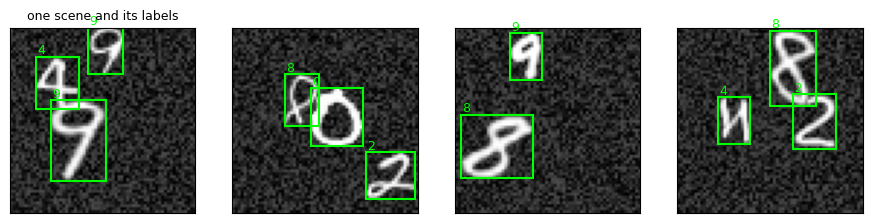

In [3]:
CANVAS = 64

def iou(a, b):
    """Intersection over union of two boxes in corners form (x1, y1, x2, y2)."""
    iw = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))        # width of the overlap (0 if they miss)
    ih = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))        # height of the overlap
    inter = iw * ih
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

def make_scene(xs, ys, n_min=1, n_max=3, max_iou=0.1, sizes=(20, 40)):
    canvas = rng.uniform(0.0, 0.3, (CANVAS, CANVAS)).astype("float32")     # grey noise background
    boxes, labels = [], []
    n = rng.integers(n_min, n_max + 1)
    tries = 0
    while len(boxes) < n and tries < 60:
        tries += 1
        k = rng.integers(len(xs))
        d = resize(xs[k], int(rng.integers(sizes[0], sizes[1] + 1)))
        ink = np.argwhere(d > 0.3)
        if len(ink) == 0:
            continue
        (r0, c0), (r1, c1) = ink.min(0), ink.max(0) + 1     # the tight box round the ink
        d = d[r0:r1, c0:c1]
        h, w = d.shape
        if w < 4:                                           # a hair-thin "1": too small to call an object
            continue
        x, y = int(rng.integers(0, CANVAS - w + 1)), int(rng.integers(0, CANVAS - h + 1))
        box = (x, y, x + w, y + h)                          # corners: x1, y1, x2, y2 in pixels
        if any(iou(box, b) > max_iou for b in boxes):
            continue
        canvas[y:y + h, x:x + w] = np.maximum(canvas[y:y + h, x:x + w], d)
        boxes.append(box)
        labels.append(int(ys[k]))
    return canvas, np.array(boxes, "float32").reshape(-1, 4), np.array(labels, int)

def make_set(xs, ys, n, **kw):
    X = np.zeros((n, CANVAS, CANVAS, 1), "float32")
    B, L = [], []
    for i in range(n):
        X[i, ..., 0], b, l = make_scene(xs, ys, **kw)
        B.append(b)
        L.append(l)
    return X, B, L

def show(ax, img, boxes=(), labels=(), color="lime", dets=(), title=""):
    ax.imshow(img.squeeze(), cmap="gray", vmin=0, vmax=1)
    for b, l in zip(boxes, labels):
        ax.add_patch(patches.Rectangle((b[0] - 0.5, b[1] - 0.5), b[2] - b[0], b[3] - b[1], fill=False, ec=color, lw=1.5))
        ax.text(b[0], b[1] - 1.5, str(l), color=color, fontsize=9)
    for d in dets:
        ax.add_patch(patches.Rectangle((d[0] - 0.5, d[1] - 0.5), d[2] - d[0], d[3] - d[1], fill=False, ec="red", lw=1.2))
        ax.text(d[0], d[3] + 5.5, f"{int(d[5])}: {d[4]:.2f}", color="red", fontsize=8)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

demo_img, demo_boxes, demo_labels = make_scene(x_train, y_train, n_min=3, n_max=3)
print("canvas", demo_img.shape, "| labels", demo_labels)
print("boxes (x1, y1, x2, y2):\n", demo_boxes)
fig, ax = plt.subplots(1, 4, figsize=(11, 3))
show(ax[0], demo_img, demo_boxes, demo_labels, title="one scene and its labels")
for a in ax[1:]:
    im, b, l = make_scene(x_train, y_train)
    show(a, im, b, l)
plt.show()

---
## Step 4 - One box, three ways to write it

The same rectangle is written in three common ways, and mixing them is the commonest detection bug.

| name | the four numbers | used by |
|---|---|---|
| corners | `x1, y1, x2, y2` | IoU, drawing, NMS |
| centre-size | `cx, cy, w, h` | what networks usually predict |
| normalised | either of the above divided by the image size, so 0 to 1 | labels that must survive a resize |

**Predict before you run:** the box `(10, 20, 30, 60)` in corners form: what are its centre, width and height?
What does IoU say if you hand it the centre-size numbers by mistake?

In [4]:
def corners_to_centre(b):
    b = np.asarray(b, "float32")
    return np.stack([(b[..., 0] + b[..., 2]) / 2, (b[..., 1] + b[..., 3]) / 2, b[..., 2] - b[..., 0], b[..., 3] - b[..., 1]], -1)

def centre_to_corners(b):
    b = np.asarray(b, "float32")
    return np.stack([b[..., 0] - b[..., 2] / 2, b[..., 1] - b[..., 3] / 2, b[..., 0] + b[..., 2] / 2, b[..., 1] + b[..., 3] / 2], -1)

box = np.array([10, 20, 30, 60], "float32")
print("corners     :", box)
print("centre-size :", corners_to_centre(box))
print("normalised  :", corners_to_centre(box) / CANVAS)
assert np.allclose(centre_to_corners(corners_to_centre(box)), box)                 # the round trip is exact
assert np.allclose(centre_to_corners(corners_to_centre(demo_boxes)), demo_boxes)
print("\nIoU of the box with itself               :", iou(box, box))
print("IoU if one copy is given as centre-size  :", round(iou(box, corners_to_centre(box)), 3), " <- no error message, only a bad number")

corners     : [10. 20. 30. 60.]
centre-size : [20. 40. 20. 40.]
normalised  : [0.312 0.625 0.312 0.625]

IoU of the box with itself               : 1.0
IoU if one copy is given as centre-size  : 0.0  <- no error message, only a bad number


---
## Step 5 - IoU, the yardstick, with tests

**Intersection over union**: the area the two boxes share, divided by the area they cover together. 1 means
identical, 0 means they do not touch. `iou` was written in Step 3; here it is tested against cases worked by
hand.

- Truth `(20, 20, 60, 60)`, a 40 x 40 box of area 1,600. Prediction shifted 10 pixels right: `(30, 20, 70, 60)`.
  Overlap 30 x 40 = 1,200. Union 1,600 + 1,600 - 1,200 = 2,000. IoU = 0.6.
- Shifted 10 right **and** 10 down: overlap 30 x 30 = 900, union 2,300, IoU = 0.391.

**Predict before you run:** a prediction with the right centre but twice the width and twice the height. What
is its IoU with the truth? Would it count as a hit at the usual threshold of 0.5?

In [5]:
truth = (20, 20, 60, 60)
cases = {
    "identical":                 (20, 20, 60, 60),
    "shifted 10 right":          (30, 20, 70, 60),
    "shifted 10 right, 10 down": (30, 30, 70, 70),
    "twice as wide and tall":    (0, 0, 80, 80),
    "half as wide and tall":     (30, 30, 50, 50),
    "touching, no overlap":      (60, 20, 100, 60),
}
for name, b in cases.items():
    print(f"{name:<28} IoU = {iou(truth, b):.3f}")
assert iou(truth, truth) == 1.0
assert abs(iou(truth, (30, 20, 70, 60)) - 0.6) < 1e-9
assert abs(iou(truth, (30, 30, 70, 70)) - 900 / 2300) < 1e-9
assert iou(truth, (0, 0, 80, 80)) == 0.25 and iou(truth, (30, 30, 50, 50)) == 0.25
assert iou(truth, (60, 20, 100, 60)) == 0.0
assert iou(truth, (30, 30, 70, 70)) == iou((30, 30, 70, 70), truth)               # symmetric

identical                    IoU = 1.000
shifted 10 right             IoU = 0.600
shifted 10 right, 10 down    IoU = 0.391
twice as wide and tall       IoU = 0.250
half as wide and tall        IoU = 0.250
touching, no overlap         IoU = 0.000


### Why we see this

IoU is strict about small shifts. A 40-pixel box moved by a quarter of its width in both directions shares
only 39% with the truth and fails the 0.5 test. A box with the right centre and twice the size scores 0.25,
the same as one of half the size: IoU punishes too big and too small alike. And it has no memory of *how*
the boxes miss: two boxes that do not touch score 0 whether they are a pixel apart or a canvas apart, which
is why plain IoU is a poor loss for boxes that start far from the truth.

---
## Step 6 - One digit: classification plus localisation

If a picture is known to hold exactly one object, detection is easy: add four outputs to a classifier. The
network below has a small convolutional trunk and two heads: ten class scores, and four box numbers
`(cx, cy, w, h)`, normalised to 0..1 and squeezed by a sigmoid.

**Predict before you run:** the trunk ends in an 8 x 8 x 64 map, flattened into `Dense(64)`. Which layer
holds most of the parameters? Count before you look.

In [6]:
X1, B1, L1 = make_set(x_train, y_train, 4000, n_min=1, n_max=1)
X1t, B1t, L1t = make_set(x_test, y_test, 500, n_min=1, n_max=1)
box1 = np.stack([corners_to_centre(b[0]) / CANVAS for b in B1])        # normalised centre-size targets
cls1 = np.array([l[0] for l in L1])

def conv_trunk(inp):
    x = inp
    for f in (16, 32, 64):
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)                                   # 64 -> 32 -> 16 -> 8
    return x

inp = layers.Input(shape=(CANVAS, CANVAS, 1))
fmap = conv_trunk(inp)                                                 # (8, 8, 64)
where = layers.Dense(64, activation="relu")(layers.Flatten()(fmap))    # keeps position: for the box
what = layers.GlobalMaxPooling2D()(fmap)                               # forgets position: for the class
localiser = keras.Model(inp, {"box": layers.Dense(4, activation="sigmoid", name="box")(where),
                              "cls": layers.Dense(10, name="cls")(what)})

TRUNK = (9 * 1 + 1) * 16 + (9 * 16 + 1) * 32 + (9 * 32 + 1) * 64      # three 3 x 3 convolutions
hand = TRUNK + (8 * 8 * 64 * 64 + 64) + (64 * 4 + 4) + (64 * 10 + 10)
print("trunk", f"{TRUNK:,}", "| Dense(64) after Flatten", f"{8 * 8 * 64 * 64 + 64:,}", "| box head", 64 * 4 + 4, "| class head", 64 * 10 + 10)
print("hand count", f"{hand:,}", "| Keras", f"{localiser.count_params():,}")
assert localiser.count_params() == hand == 286_414

localiser.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss={"box": "mse", "cls": keras.losses.SparseCategoricalCrossentropy(from_logits=True)},
                  loss_weights={"box": 50.0, "cls": 1.0})
t = time.time()
localiser.fit(X1, {"box": box1, "cls": cls1}, batch_size=64, epochs=8, verbose=0)

def localiser_boxes(X):
    out = localiser.predict(X, verbose=0)
    return centre_to_corners(out["box"] * CANVAS), out["cls"].argmax(-1)

pb, pc = localiser_boxes(X1t)
ious1 = np.array([iou(pb[i], B1t[i][0]) for i in range(len(X1t))])
acc1 = np.mean(pc == np.array([l[0] for l in L1t]))
print(f"trained in {time.time() - t:.0f}s on 4,000 one-digit scenes")
print(f"one digit : class accuracy {100 * acc1:.1f}% | mean IoU {ious1.mean():.3f} | boxes with IoU >= 0.5: {100 * np.mean(ious1 >= 0.5):.1f}%")

trunk 23,296 | Dense(64) after Flatten 262,208 | box head 260 | class head 650
hand count 286,414 | Keras 286,414


trained in 22s on 4,000 one-digit scenes
one digit : class accuracy 90.4% | mean IoU 0.651 | boxes with IoU >= 0.5: 86.6%


---
## Step 7 - Now hand it two digits

The localiser has four box outputs. A scene with two digits has eight box numbers of truth. Nothing in the
network can hold the second box.

**Predict before you run:** given two digits, where will the single box go? On the bigger digit, on the first
one, or somewhere else?

two digits: the one box reaches IoU >= 0.5 with EITHER digit in 12.4% of scenes (mean best IoU 0.303)
            its centre lies inside NEITHER digit's box in 45.2% of scenes
            and even a perfect box would find 1 of 2 digits: recall can never pass 50%


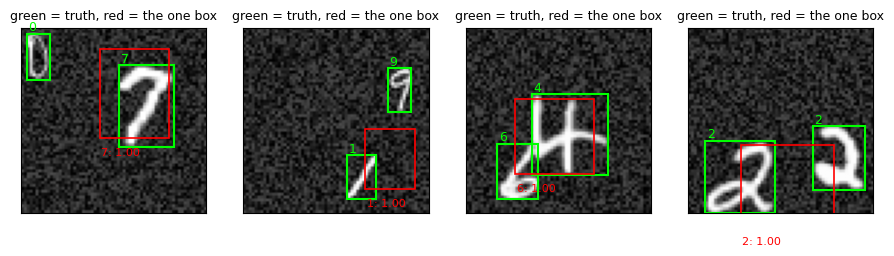

In [7]:
X2, B2, L2 = make_set(x_test, y_test, 500, n_min=2, n_max=2)
pb2, pc2 = localiser_boxes(X2)
best = np.array([max(iou(pb2[i], b) for b in B2[i]) for i in range(len(X2))])
between = 0
for i in range(len(X2)):
    cx, cy = (pb2[i][0] + pb2[i][2]) / 2, (pb2[i][1] + pb2[i][3]) / 2
    inside = [b[0] <= cx <= b[2] and b[1] <= cy <= b[3] for b in B2[i]]
    between += not any(inside)
print(f"two digits: the one box reaches IoU >= 0.5 with EITHER digit in {100 * np.mean(best >= 0.5):.1f}% of scenes (mean best IoU {best.mean():.3f})")
print(f"            its centre lies inside NEITHER digit's box in {100 * between / len(X2):.1f}% of scenes")
print(f"            and even a perfect box would find 1 of 2 digits: recall can never pass 50%")
fig, ax = plt.subplots(1, 4, figsize=(11, 3))
for k, a in enumerate(ax):
    show(a, X2[k], B2[k], L2[k], dets=[list(pb2[k]) + [1.0, pc2[k]]], title="green = truth, red = the one box")
plt.show()
LOCALISER = dict(acc=acc1, miou=ious1.mean(), hit=np.mean(ious1 >= 0.5), two_hit=np.mean(best >= 0.5), between=between / len(X2))

### Why we see this

With one digit the four extra outputs do their job. With two, the network was trained to give the box that
minimises squared error, and when two answers are possible the lowest-error guess is a compromise: a box
that leans towards the average of the two. In 45% of these scenes its centre lay inside neither digit's box,
and it reached IoU 0.5 with either digit in only 12%. This is the
reason detection is not "classification with four more numbers". A fixed set of outputs cannot describe a
list of unknown length, and averaging two right answers gives a wrong one.

---
## Step 8 - The detection data: one to three digits

**Predict before you run:** 10,000 scenes with one, two or three digits, each count equally likely when the
digits fit. About how many digits is that in all?

In [8]:
N_TRAIN, N_TEST = 10_000, 1_000
Xtr, Btr, Ltr = make_set(x_train, y_train, N_TRAIN)
Xte, Bte, Lte = make_set(x_test, y_test, N_TEST)
n_obj_train = sum(len(b) for b in Btr)
n_obj_test = sum(len(b) for b in Bte)
print("train scenes", Xtr.shape, "| digits", f"{n_obj_train:,}", "| per scene", np.bincount([len(b) for b in Btr])[1:])
print("test  scenes", Xte.shape, " | digits", f"{n_obj_test:,}", " | per scene", np.bincount([len(b) for b in Bte])[1:])
hh = np.concatenate([b[:, 3] - b[:, 1] for b in Btr])
ww = np.concatenate([b[:, 2] - b[:, 0] for b in Btr])
print(f"box height: {hh.min():.0f} to {hh.max():.0f} pixels (mean {hh.mean():.1f}) | width: {ww.min():.0f} to {ww.max():.0f} (mean {ww.mean():.1f})")

train scenes (10000, 64, 64, 1) | digits 19,987 | per scene [3348 3317 3335]
test  scenes (1000, 64, 64, 1)  | digits 2,060  | per scene [309 322 369]
box height: 7 to 30 pixels (mean 21.1) | width: 4 to 30 (mean 16.0)


---
## Step 9 - The grid, and target assignment (the heart of the lab)

The way out of Step 7 is **dense prediction**: lay an 8 x 8 grid over the canvas (each cell is 8 x 8 pixels)
and let *every cell* make one prediction of 15 numbers:

| index | number | meaning |
|---|---|---|
| 0 | objectness | is the centre of an object in this cell? |
| 1, 2 | `tx, ty` | where in the cell the centre is, 0 to 1 |
| 3, 4 | `tw, th` | the box's width and height as a fraction of the canvas |
| 5 to 14 | ten class scores | which digit |

The network's output is therefore `(8, 8, 15)`: 64 predictions, always, whatever the picture holds. Training
needs a target of the same shape, and building it is **target assignment**: deciding which cell is
responsible for which digit. Our rule: **the cell that contains the centre of the digit's box.** Every other
cell is told "nothing here".

Read `encode` line by line. It is short, and it is where detection bugs live.

**Predict before you run:** a digit with box `(18, 32, 34, 52)`. Which row and column of the grid is
responsible for it, and what are its five target numbers?

box (18, 32, 34, 52): centre (26, 42) -> row 5 col 3
target at that cell: [1.    0.25  0.25  0.25  0.312] | class slot: 7

targets (10000, 8, 8, 15)
digits assigned to a cell: 19,987 | lost because the cell was taken: 0 of 19,987
cells that hold an object: 19,987 of 640,000 = 3.12%  (the other 96.88% say 'nothing here')


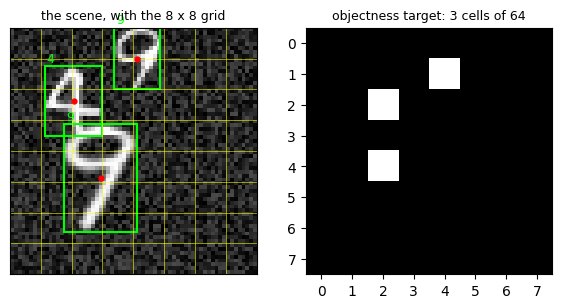

In [9]:
GRID = 8
CELL = CANVAS // GRID            # 8 pixels per cell
DEPTH = 5 + 10                   # objectness, 4 box numbers, 10 classes

def encode(boxes, labels):
    """Truth (corner boxes + labels) -> the (8, 8, 15) target the network is trained towards."""
    target = np.zeros((GRID, GRID, DEPTH), "float32")        # start with "nothing anywhere"
    lost = []
    for k, ((x1, y1, x2, y2), c) in enumerate(zip(boxes, labels)):
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2                # 1. the centre of the box, in pixels
        col = min(int(cx // CELL), GRID - 1)                 # 2. the cell that centre falls in
        row = min(int(cy // CELL), GRID - 1)                 #    (y picks the row, x picks the column)
        if target[row, col, 0] == 1:                         # 3. that cell is already taken: one prediction
            lost.append(k)                                   #    per cell, so this digit cannot be represented
            continue
        target[row, col, 0] = 1                              # 4. objectness: yes
        target[row, col, 1] = cx / CELL - col                # 5. centre offset inside the cell, 0..1
        target[row, col, 2] = cy / CELL - row
        target[row, col, 3] = (x2 - x1) / CANVAS             # 6. width and height, fraction of the canvas
        target[row, col, 4] = (y2 - y1) / CANVAS
        target[row, col, 5 + c] = 1                          # 7. the class, one-hot
    return target, lost

t_demo, _ = encode(np.array([[18, 32, 34, 52]], "float32"), [7])
row, col = np.argwhere(t_demo[..., 0] == 1)[0]
print("box (18, 32, 34, 52): centre (26, 42) -> row", row, "col", col)
print("target at that cell:", t_demo[row, col, :5], "| class slot:", t_demo[row, col, 5:].argmax())
assert (row, col) == (5, 3) and np.allclose(t_demo[row, col, :5], [1, 0.25, 0.25, 0.25, 0.3125])
assert t_demo.sum() == 1 + 0.25 + 0.25 + 0.25 + 0.3125 + 1          # every other number is zero

enc = [encode(b, l) for b, l in zip(Btr, Ltr)]
Ttr = np.stack([e[0] for e in enc])
n_lost = sum(len(e[1]) for e in enc)
n_assigned = int(Ttr[..., 0].sum())
assert n_assigned + n_lost == n_obj_train
print("\ntargets", Ttr.shape)
print(f"digits assigned to a cell: {n_assigned:,} | lost because the cell was taken: {n_lost} of {n_obj_train:,}")
print(f"cells that hold an object: {n_assigned:,} of {Ttr[..., 0].size:,} = {100 * Ttr[..., 0].mean():.2f}%  (the other {100 - 100 * Ttr[..., 0].mean():.2f}% say 'nothing here')")

t3, _ = encode(demo_boxes, demo_labels)
fig, ax = plt.subplots(1, 2, figsize=(7, 3.4))
show(ax[0], demo_img, demo_boxes, demo_labels, title="the scene, with the 8 x 8 grid")
for g in range(1, GRID):
    ax[0].axhline(g * CELL - 0.5, color="yellow", lw=0.4); ax[0].axvline(g * CELL - 0.5, color="yellow", lw=0.4)
for b in demo_boxes:
    ax[0].plot((b[0] + b[2]) / 2 - 0.5, (b[1] + b[3]) / 2 - 0.5, "r.", ms=7)
ax[1].imshow(t3[..., 0], cmap="gray"); ax[1].set_title("objectness target: 3 cells of 64", fontsize=9)
ax[1].set_xticks(range(GRID)); ax[1].set_yticks(range(GRID))
plt.show()

### Why we see this

Three things to notice. First, **the target is almost all zeros**: about three cells in a hundred hold an
object. A network that answered "nothing here" everywhere would be right about objectness in the other 97,
which is why the loss in Step 12 treats empty cells differently. Second, **no digit was lost here**, but
`encode` has a branch for it: when two centres land in the same cell, one prediction cannot stand for both,
and the second digit is dropped from training without a word. Our digits are large and barely overlap, so
two centres never came within one 8-pixel cell. Step 20 crowds the scenes and the branch fires. Third, the
offsets `tx, ty` are small numbers between 0 and 1 measured from the cell's own corner: the cell already says
roughly where the object is, and the network only has to add the correction.

---
## Step 10 - Decoding is the assignment run backwards

`decode` turns an `(8, 8, 15)` array back into a list of boxes: for every cell whose score passes a
threshold, undo steps 5 and 6 of `encode`. Each detection is a row `(x1, y1, x2, y2, score, class)`, where
**score = objectness x probability of the best class**.

The first test of any detector, before any training: **encode the truth, decode it, and get the truth back.**
If that fails, no amount of training will help.

**Predict before you run:** will the round trip be exact for every digit in the training set?

In [10]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def decode(pred, score_thr=0.3, from_logits=True):
    """An (8, 8, 15) prediction -> array of detections (x1, y1, x2, y2, score, class)."""
    if from_logits:
        obj = sigmoid(pred[..., 0])
        box = sigmoid(pred[..., 1:5])
        e = np.exp(pred[..., 5:] - pred[..., 5:].max(-1, keepdims=True))
        cls = e / e.sum(-1, keepdims=True)                    # softmax over the ten classes
    else:
        obj, box, cls = pred[..., 0], pred[..., 1:5], pred[..., 5:]
    dets = []
    for row in range(GRID):
        for col in range(GRID):
            score = obj[row, col] * cls[row, col].max()
            if score < score_thr:
                continue
            cx = (col + box[row, col, 0]) * CELL              # undo step 5 of encode
            cy = (row + box[row, col, 1]) * CELL
            w = box[row, col, 2] * CANVAS                     # undo step 6
            h = box[row, col, 3] * CANVAS
            dets.append([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2, score, cls[row, col].argmax()])
    return np.array(dets, "float32").reshape(-1, 6)

exact = total = 0
for b, l, (tgt, lost) in zip(Btr[:2000], Ltr[:2000], enc[:2000]):
    d = decode(tgt, from_logits=False)
    keep = [k for k in range(len(b)) if k not in lost]
    assert len(d) == len(keep)
    for k in keep:
        j = np.argmax([iou(b[k], r) for r in d])
        exact += np.allclose(d[j, :4], b[k], atol=1e-3) and int(d[j, 5]) == l[k]
        total += 1
print(f"round trip on 2,000 scenes: {exact:,} of {total:,} assigned digits recovered exactly")
assert exact == total

round trip on 2,000 scenes: 3,981 of 3,981 assigned digits recovered exactly


---
## Step 11 - The detector: a small convolutional network with a 1 x 1 head

Three `Conv2D` + `MaxPooling2D` stages shrink 64 x 64 to 8 x 8, so **one position of the final map is one grid
cell**. Two more 3 x 3 convolutions at 8 x 8 widen what each cell can see, and a 1 x 1 convolution with 15
filters writes the 15 numbers for each cell. There is no `Flatten` and no `Dense`: the same small set of
weights makes the prediction at every cell (Chapter 14's parameter sharing).

**Predict before you run:** the head is `Conv2D(15, 1)` on 64 channels. How many parameters? And how far can
one cell see, in pixels of the canvas, after five 3 x 3 convolutions and three poolings?

In [11]:
def build_detector():
    return keras.Sequential([
        layers.Input(shape=(CANVAS, CANVAS, 1)),
        layers.Conv2D(16, 3, padding="same", activation="relu", name="conv1"),
        layers.MaxPooling2D(name="pool1"),                                       # 64 -> 32
        layers.Conv2D(32, 3, padding="same", activation="relu", name="conv2"),
        layers.MaxPooling2D(name="pool2"),                                       # 32 -> 16
        layers.Conv2D(64, 3, padding="same", activation="relu", name="conv3"),
        layers.MaxPooling2D(name="pool3"),                                       # 16 -> 8: one position per cell
        layers.Conv2D(64, 3, padding="same", activation="relu", name="conv4"),
        layers.Conv2D(64, 3, padding="same", activation="relu", name="conv5"),
        layers.Conv2D(DEPTH, 1, name="head"),                                    # 15 raw numbers per cell
    ], name="grid_detector")

detector = build_detector()
counts = {"conv1": (9 * 1 + 1) * 16, "conv2": (9 * 16 + 1) * 32, "conv3": (9 * 32 + 1) * 64,
          "conv4": (9 * 64 + 1) * 64, "conv5": (9 * 64 + 1) * 64, "head": (1 * 64 + 1) * 15}
for layer in detector.layers:
    print(f"{layer.name:<6} {str(layer.output.shape):<20} {layer.count_params():>7,}")
    if layer.name in counts:
        assert layer.count_params() == counts[layer.name]
print("hand count", f"{sum(counts.values()):,}", "| Keras", f"{detector.count_params():,}")
assert detector.count_params() == sum(counts.values()) == 98_127
assert detector.output_shape[1:] == (GRID, GRID, DEPTH)

# receptive field of one output cell: each 3 x 3 conv adds 2 x (current stride); each pool doubles the stride
rf, stride = 1, 1
for kind in ["conv", "pool", "conv", "pool", "conv", "pool", "conv", "conv"]:
    if kind == "conv":
        rf += 2 * stride
    else:
        rf += stride
        stride *= 2
print("receptive field of one cell:", rf, "x", rf, "pixels | stride", stride)
assert (rf, stride) == (54, 8)

conv1  (None, 64, 64, 16)       160
pool1  (None, 32, 32, 16)         0
conv2  (None, 32, 32, 32)     4,640
pool2  (None, 16, 16, 32)         0
conv3  (None, 16, 16, 64)    18,496
pool3  (None, 8, 8, 64)           0
conv4  (None, 8, 8, 64)      36,928
conv5  (None, 8, 8, 64)      36,928
head   (None, 8, 8, 15)         975
hand count 98,127 | Keras 98,127
receptive field of one cell: 54 x 54 pixels | stride 8


---
## Step 12 - The loss is three losses added

For each scene:

1. **Objectness**, at all 64 cells: binary cross-entropy. Empty cells are multiplied by `w_noobj` (0.5),
   because there are about thirty of them for every cell with an object.
2. **Box**, only at cells that own an object: squared error on the four box numbers, multiplied by `w_box`.
3. **Class**, only at cells that own an object: softmax cross-entropy over ten classes.

The mask `obj = y_true[..., 0]` does the "only at cells that own an object" part. An empty cell's box and
class outputs are never scored: the network may write anything there.

**Predict before you run:** a network that outputs all zeros (logits) on a scene with 2 digits and 62 empty
cells. The objectness part is `ln 2` per cell before weighting. What are the three parts, by hand?

In [12]:
W_BOX, W_NOOBJ = 50.0, 0.5

def loss_parts(y_true, y_pred, w_box=W_BOX, w_noobj=W_NOOBJ):
    obj = y_true[..., 0]                                                        # 1 where a cell owns a digit
    bce = tf.nn.sigmoid_cross_entropy_with_logits(labels=obj, logits=y_pred[..., 0])
    l_obj = tf.reduce_sum(obj * bce + w_noobj * (1.0 - obj) * bce, axis=[1, 2])
    sq = tf.reduce_sum(tf.square(y_true[..., 1:5] - tf.sigmoid(y_pred[..., 1:5])), axis=-1)
    l_box = w_box * tf.reduce_sum(obj * sq, axis=[1, 2])
    ce = tf.nn.softmax_cross_entropy_with_logits(labels=y_true[..., 5:], logits=y_pred[..., 5:])
    l_cls = tf.reduce_sum(obj * ce, axis=[1, 2])
    return l_obj, l_box, l_cls

def make_loss(w_box=W_BOX, w_noobj=W_NOOBJ):
    def det_loss(y_true, y_pred):
        return tf.add_n(loss_parts(y_true, y_pred, w_box, w_noobj))
    return det_loss

def obj_part(y_true, y_pred): return loss_parts(y_true, y_pred)[0]
def box_part(y_true, y_pred): return loss_parts(y_true, y_pred)[1]
def cls_part(y_true, y_pred): return loss_parts(y_true, y_pred)[2]

# test 1: all-zero logits on a scene with 2 digits, against a hand count
k2 = next(i for i in range(N_TRAIN) if Ttr[i, ..., 0].sum() == 2)
y = tf.constant(Ttr[k2:k2 + 1])
lo, lb, lc = [float(v[0]) for v in loss_parts(y, tf.zeros_like(y))]
hand_obj = 2 * np.log(2) + 0.5 * 62 * np.log(2)
hand_box = 50 * float(np.sum((Ttr[k2][Ttr[k2, ..., 0] == 1][:, 1:5] - 0.5) ** 2))
hand_cls = 2 * np.log(10)
print(f"all-zero logits: objectness {lo:.3f} (hand {hand_obj:.3f}) | box {lb:.3f} (hand {hand_box:.3f}) | class {lc:.3f} (hand {hand_cls:.3f})")
assert np.allclose([lo, lb, lc], [hand_obj, hand_box, hand_cls], atol=1e-3)

# test 2: a near-perfect prediction scores near zero
big = 20.0
perfect = np.full_like(Ttr[k2:k2 + 1], -big)
perfect[..., 0] = np.where(Ttr[k2:k2 + 1, ..., 0] == 1, big, -big)
perfect[..., 1:5] = np.log(np.clip(Ttr[k2:k2 + 1, ..., 1:5], 1e-6, 1 - 1e-6) / (1 - np.clip(Ttr[k2:k2 + 1, ..., 1:5], 1e-6, 1 - 1e-6)))
perfect[..., 5:] = np.where(Ttr[k2:k2 + 1, ..., 5:] == 1, big, -big)
print("perfect logits : total", round(float(make_loss()(y, tf.constant(perfect))[0]), 5))
assert float(make_loss()(y, tf.constant(perfect))[0]) < 1e-3

all-zero logits: objectness 22.874 (hand 22.874) | box 13.452 (hand 13.452) | class 4.605 (hand 4.605)
perfect logits : total 0.0


---
## Step 13 - Train the detector

Eighteen passes over 10,000 scenes, Adam, with the learning rate falling along a cosine. The three parts of the
loss are printed separately every epoch.

**Predict before you run:** which of the three parts will fall fastest, and which will still be the largest at
the end?

trained in 129s

epoch   total   objectness   box    class
   1   16.935      4.422   7.985   4.529
   2    8.852      1.840   3.708   3.304
   3    6.298      1.524   2.919   1.856
   4    4.973      1.334   2.403   1.236
   5    4.211      1.196   2.078   0.937
   6    3.696      1.097   1.823   0.776
   7    3.335      1.023   1.640   0.672
   8    3.070      0.968   1.512   0.591
   9    2.864      0.922   1.409   0.533
  10    2.699      0.885   1.326   0.487
  11    2.570      0.853   1.268   0.449
  12    2.460      0.827   1.212   0.421
  13    2.326      0.802   1.131   0.393
  14    2.225      0.780   1.075   0.371
  15    2.150      0.762   1.032   0.356
  16    2.096      0.749   1.002   0.345
  17    2.056      0.739   0.981   0.336
  18    2.029      0.732   0.967   0.329


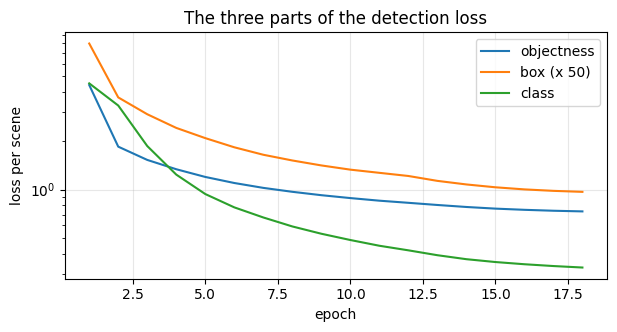

In [13]:
EPOCHS, BATCH = 18, 64
steps = EPOCHS * (N_TRAIN // BATCH + 1)
detector.compile(optimizer=keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(2e-3, steps, alpha=0.05)),
                 loss=make_loss(), metrics=[obj_part, box_part, cls_part])
t = time.time()
hist = detector.fit(Xtr, Ttr, batch_size=BATCH, epochs=EPOCHS, verbose=0)
print(f"trained in {time.time() - t:.0f}s\n")
print("epoch   total   objectness   box    class")
for e in range(EPOCHS):
    print(f"{e + 1:>4}  {hist.history['loss'][e]:7.3f}  {hist.history['obj_part'][e]:9.3f}  {hist.history['box_part'][e]:6.3f}  {hist.history['cls_part'][e]:6.3f}")
plt.figure(figsize=(7, 3.2))
for key, name in [("obj_part", "objectness"), ("box_part", "box (x 50)"), ("cls_part", "class")]:
    plt.plot(range(1, EPOCHS + 1), hist.history[key], label=name)
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("loss per scene"); plt.legend(); plt.grid(alpha=0.3)
plt.title("The three parts of the detection loss"); plt.show()

### Why we see this

The three parts fall at different speeds because they are three different problems. Objectness starts near
22.9 (Step 12) and is down to about 4.4 after one epoch: "mostly nothing" is learnt almost at once. In that
same epoch the *class* part hardly moves from its starting value of about 4.6: until the network has found
where the digits are, there is nothing to classify. Then it falls steeply, and by the end it is the smallest
of the three.

The box part is printed after multiplying by 50, and with that weight it ends as the largest. Without the
weight its raw size would be about 0.02 per scene, and the optimiser would spend its effort on the other two
(Step 21 measures what that costs). None of the three has stopped falling: this is a two-minute run.

---
## Step 14 - Look at the raw predictions

Run the detector on the test scenes and decode with a low score threshold (0.05), so that weak predictions are
visible too.

**Predict before you run:** each digit has exactly one responsible cell. Will each digit get exactly one box?

prediction array: (1000, 8, 8, 15)
raw boxes with score >= 0.05: 3,377 for 2,060 digits (1.64 per digit)
raw boxes with score >= 0.50: 2,044


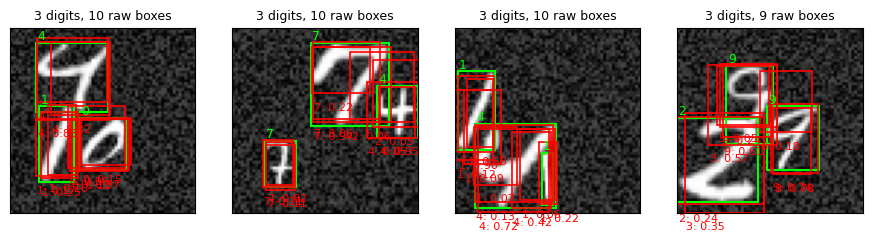

In [14]:
Pte = detector.predict(Xte, verbose=0)
print("prediction array:", Pte.shape)
raw = [decode(p, score_thr=0.05) for p in Pte]
n_raw = sum(len(d) for d in raw)
print(f"raw boxes with score >= 0.05: {n_raw:,} for {n_obj_test:,} digits ({n_raw / n_obj_test:.2f} per digit)")
strong = [d[d[:, 4] >= 0.5] for d in raw]
print(f"raw boxes with score >= 0.50: {sum(len(d) for d in strong):,}")
many = np.argsort([-(len(d) - len(b)) for d, b in zip(raw, Bte)])[:4]
fig, ax = plt.subplots(1, 4, figsize=(11, 3))
for a, k in zip(ax, many):
    show(a, Xte[k], Bte[k], Lte[k], dets=raw[k], title=f"{len(Bte[k])} digits, {len(raw[k])} raw boxes")
plt.show()

---
## Step 15 - Non-maximum suppression, by hand, with tests

When a centre lies near a cell border, the neighbouring cell often fires too, and one digit gets two boxes.
**Non-maximum suppression (NMS)** cleans up: sort the boxes by score; keep the best; delete every remaining
box that overlaps it by more than a threshold; repeat with the best of what is left.

Worked by hand, with threshold 0.45:

| box | corners | score | IoU with A | IoU with C | fate |
|---|---|---|---|---|---|
| A | (10, 10, 50, 50) | 0.9 | | | kept: the best |
| B | (12, 14, 52, 54) | 0.8 | 0.747 | | dropped: a duplicate of A |
| C | (60, 10, 100, 50) | 0.7 | 0 | | kept |
| D | (30, 10, 70, 50) | 0.6 | 0.333 | 0.143 | kept at 0.45, dropped at 0.3 |

**Predict before you run:** D overlaps A by a third. Is D a duplicate of A, or a real object standing next to
it? What does NMS know that could tell the two apart?

IoU A-B 0.747 | A-D 0.333 | C-D 0.143
kept at 0.45: [0.9 0.7 0.6]
kept at 0.30: [0.9 0.7]

test set: 3,377 raw boxes -> 2,142 after NMS, for 2,060 digits


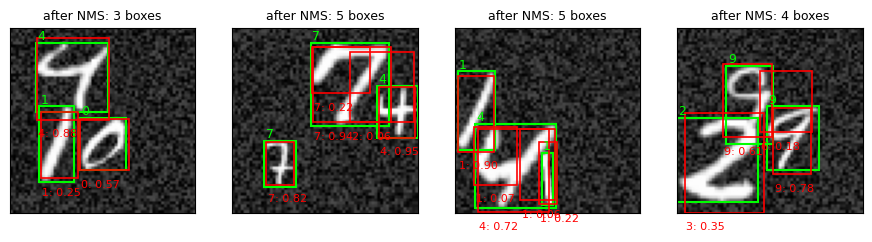

In [15]:
def nms(dets, iou_thr=0.45):
    """Greedy non-maximum suppression. dets: rows (x1, y1, x2, y2, score, class)."""
    order = np.argsort(-dets[:, 4])                      # best score first
    keep = []
    for i in order:
        if all(iou(dets[i], dets[j]) <= iou_thr for j in keep):
            keep.append(i)                               # nothing already kept overlaps it too much
    return dets[keep]

toy = np.array([[10, 10, 50, 50, 0.9, 3], [12, 14, 52, 54, 0.8, 3], [60, 10, 100, 50, 0.7, 5], [30, 10, 70, 50, 0.6, 8]], "float32")
print("IoU A-B", round(iou(toy[0], toy[1]), 3), "| A-D", round(iou(toy[0], toy[3]), 3), "| C-D", round(iou(toy[2], toy[3]), 3))
print("kept at 0.45:", nms(toy, 0.45)[:, 4])
print("kept at 0.30:", nms(toy, 0.30)[:, 4])
assert abs(iou(toy[0], toy[1]) - 1368 / 1832) < 1e-6 and abs(iou(toy[0], toy[3]) - 1 / 3) < 1e-6 and abs(iou(toy[2], toy[3]) - 1 / 7) < 1e-6
assert np.allclose(nms(toy, 0.45)[:, 4], [0.9, 0.7, 0.6])
assert np.allclose(nms(toy, 0.30)[:, 4], [0.9, 0.7])
assert len(nms(toy, 1.0)) == 4 and len(nms(toy[:0])) == 0             # threshold 1 keeps everything; empty in, empty out
assert np.allclose(nms(toy[::-1], 0.45)[:, 4], [0.9, 0.7, 0.6])       # the input order does not matter

final = [nms(d) for d in raw]
print(f"\ntest set: {n_raw:,} raw boxes -> {sum(len(d) for d in final):,} after NMS, for {n_obj_test:,} digits")
fig, ax = plt.subplots(1, 4, figsize=(11, 3))
for a, k in zip(ax, many):
    show(a, Xte[k], Bte[k], Lte[k], dets=final[k], title=f"after NMS: {len(final[k])} boxes")
plt.show()

---
## Step 16 - Score it: true positives, precision and recall

Accuracy has no meaning for a detector (accuracy over what? there is no fixed list of questions). Instead,
every detection is judged, best score first:

- It is a **true positive** if it has the right class and its IoU with a not-yet-matched true box of that
  class is at least 0.5.
- Otherwise it is a **false positive**. That includes a second box on a digit that was already matched.
- A true box that nothing matched is a **false negative** (a miss).

**Precision** = true positives / detections made. **Recall** = true positives / true objects (Chapter 12).

**Predict before you run:** keep only detections with score at least 0.5. Then tighten the IoU test from 0.5
to 0.75. Which moves more, precision or recall?

In [16]:
def match_scene(dets, gt_boxes, gt_labels, iou_thr=0.5):
    """Judge one scene's detections. Returns [(score, class, is_true_positive)] and the matched truth indices."""
    used, out = set(), []
    for d in dets[np.argsort(-dets[:, 4])]:
        best_iou, best_k = 0.0, -1
        for k, (b, l) in enumerate(zip(gt_boxes, gt_labels)):
            if l == int(d[5]) and k not in used and iou(d, b) > best_iou:
                best_iou, best_k = iou(d, b), k
        hit = best_iou >= iou_thr
        if hit:
            used.add(best_k)
        out.append((float(d[4]), int(d[5]), hit))
    return out, used

def judge(det_list, gts, lbls, iou_thr=0.5):
    recs = []
    for d, b, l in zip(det_list, gts, lbls):
        recs += match_scene(d, b, l, iou_thr)[0]
    return recs

def precision_recall(recs, n_true, score_thr=0.5):
    tp = sum(1 for s, c, hit in recs if s >= score_thr and hit)
    n = sum(1 for s, c, hit in recs if s >= score_thr)
    return tp / max(n, 1), tp / n_true, tp, n - tp, n_true - tp

# a tiny test with a known answer: 2 true boxes; detections = 1 hit, 1 duplicate, 1 wrong class
gt_b, gt_l = np.array([[10, 10, 30, 30], [40, 40, 60, 60]], "float32"), np.array([3, 5])
dd = np.array([[10, 10, 30, 30, 0.9, 3], [11, 11, 31, 31, 0.8, 3], [40, 40, 60, 60, 0.7, 4]], "float32")
r, used = match_scene(dd, gt_b, gt_l)
assert [h for _, _, h in r] == [True, False, False] and used == {0}
assert precision_recall(r, 2, 0.5)[:2] == (1 / 3, 1 / 2)

for thr in (0.5, 0.75):
    recs = judge(final, Bte, Lte, thr)
    p, rc, tp, fp, fn = precision_recall(recs, n_obj_test)
    print(f"IoU >= {thr:<4} score >= 0.5: precision {p:.3f} | recall {rc:.3f} | true pos {tp:,} | false pos {fp:,} | missed {fn:,}")
recs50 = judge(final, Bte, Lte, 0.5)
P50, R50, TP50, FP50, FN50 = precision_recall(recs50, n_obj_test)

IoU >= 0.5  score >= 0.5: precision 0.941 | recall 0.862 | true pos 1,775 | false pos 111 | missed 285
IoU >= 0.75 score >= 0.5: precision 0.812 | recall 0.744 | true pos 1,532 | false pos 354 | missed 528


---
## Step 17 - The precision-recall curve and average precision

The score threshold of 0.5 was a choice. Lower it and you find more digits (recall up) and raise more false
alarms (precision down). Sweeping it through every value draws the **precision-recall curve**, and the area
under that curve is the **average precision (AP)**: one number that does not depend on the threshold you
happened to pick.

AP is computed per class and averaged over the ten classes: **mAP**. We compute it at IoU 0.5 (lenient), at
0.75 (strict), and averaged over the ten thresholds 0.50, 0.55, ..., 0.95, which is the convention the COCO
benchmark made standard.

**Predict before you run:** will the strict number be a little lower than the lenient one, or a lot?

AP at IoU 0.5 per class: [0.926 0.906 0.889 0.914 0.942 0.894 0.9   0.891 0.886 0.903]
mAP at IoU 0.50      : 0.905
mAP at IoU 0.75      : 0.711
mAP averaged over IoU 0.50 to 0.95: 0.601
mAP at each threshold: [0.905 0.893 0.881 0.857 0.804 0.711 0.545 0.326 0.081 0.004]


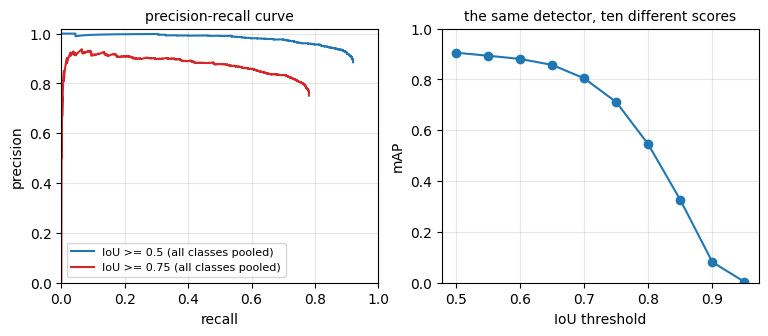

In [17]:
def pr_curve(recs, n_true):
    recs = sorted(recs, key=lambda r: -r[0])
    tp = np.cumsum([r[2] for r in recs])
    fp = np.cumsum([not r[2] for r in recs])
    return tp / (tp + fp), tp / n_true                       # precision, recall after each detection

def average_precision(recs, n_true):
    if n_true == 0 or len(recs) == 0:
        return 0.0
    prec, rec = pr_curve(recs, n_true)
    prec = np.maximum.accumulate(prec[::-1])[::-1]           # make precision non-increasing (the usual envelope)
    return float(np.sum(np.diff(np.concatenate([[0.0], rec])) * prec))   # area under the staircase

def mean_ap(det_list, gts, lbls, iou_thr=0.5):
    recs = judge(det_list, gts, lbls, iou_thr)
    n_true = np.bincount(np.concatenate(lbls), minlength=10)
    aps = [average_precision([r for r in recs if r[1] == c], n_true[c]) for c in range(10)]
    return float(np.mean(aps)), aps

# test: two detections, the first right and the second wrong, one true object -> AP 1; reversed -> AP 0.5
assert average_precision([(0.9, 0, True), (0.8, 0, False)], 1) == 1.0
assert average_precision([(0.9, 0, False), (0.8, 0, True)], 1) == 0.5
assert average_precision([(0.9, 0, True)], 2) == 0.5         # found one of two: the curve stops at recall 0.5

MAP50, ap50 = mean_ap(final, Bte, Lte, 0.5)
MAP75, _ = mean_ap(final, Bte, Lte, 0.75)
thresholds = np.arange(0.5, 0.96, 0.05)
maps = [mean_ap(final, Bte, Lte, float(t))[0] for t in thresholds]
MAP_COCO = float(np.mean(maps))
print("AP at IoU 0.5 per class:", np.round(ap50, 3))
print(f"mAP at IoU 0.50      : {MAP50:.3f}")
print(f"mAP at IoU 0.75      : {MAP75:.3f}")
print(f"mAP averaged over IoU 0.50 to 0.95: {MAP_COCO:.3f}")
print("mAP at each threshold:", np.round(maps, 3))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
for thr, c in [(0.5, "tab:blue"), (0.75, "tab:red")]:
    prec, rec = pr_curve(judge(final, Bte, Lte, thr), n_obj_test)
    ax[0].plot(rec, prec, color=c, label=f"IoU >= {thr} (all classes pooled)")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1.02)
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3); ax[0].set_title("precision-recall curve", fontsize=10)
ax[1].plot(thresholds, maps, "o-"); ax[1].set_xlabel("IoU threshold"); ax[1].set_ylabel("mAP"); ax[1].set_ylim(0, 1)
ax[1].grid(alpha=0.3); ax[1].set_title("the same detector, ten different scores", fontsize=10)
plt.show()

### Why we see this

The same detector, with the same weights, gets three very different "scores" depending on how strictly a hit
is defined: 0.905 at IoU 0.5, 0.711 at 0.75, and 0.601 averaged over 0.50 to 0.95. At IoU 0.5 a box may be
visibly loose and still count. At 0.75 it must fit well, and at 0.95 it must be nearly pixel-perfect, which
this small network almost never manages (0.004). That is why a detection score means nothing until you know
its threshold, and why the number averaged over 0.50 to 0.95 is always lower than the number at 0.5.

These are scores on clean pasted digits. They are not what detectors reach on photographs.

---
## Step 18 - What kinds of mistake does it make?

A single number hides the reasons. Sort every false positive (score at least 0.5, after NMS) by what went
wrong, and every miss by whether the detector could have found it at all.

**Predict before you run:** which will be the commonest false positive: the wrong class in the right place,
the right class with a loose box, a second box on an already-found digit, or a box on empty background?

In [18]:
def error_kinds(det_list, gts, lbls, score_thr=0.5, iou_thr=0.5):
    kinds = dict(wrong_class=0, loose_box=0, duplicate=0, background=0)
    miss = dict(collision=0, right_but_under_threshold=0, other=0)
    for d, b, l in zip(det_list, gts, lbls):
        weak = d[d[:, 4] < score_thr]                       # boxes the score threshold threw away
        d = d[d[:, 4] >= score_thr]
        recs, used = match_scene(d, b, l, iou_thr)
        order = np.argsort(-d[:, 4])
        for (s, c, hit), i in zip(recs, order):
            if hit:
                continue
            ious = np.array([iou(d[i], bb) for bb in b]) if len(b) else np.zeros(0)
            k = int(ious.argmax()) if len(ious) else -1
            if k < 0 or ious[k] < 0.1:
                kinds["background"] += 1
            elif ious[k] >= iou_thr and l[k] != c:
                kinds["wrong_class"] += 1
            elif ious[k] >= iou_thr and l[k] == c:
                kinds["duplicate"] += 1
            else:
                kinds["loose_box"] += 1
        lost = encode(b, l)[1]                               # digits that no cell could be responsible for
        for k in range(len(b)):
            if k in used:
                continue
            if k in lost:
                miss["collision"] += 1
            elif any(int(w[5]) == l[k] and iou(w, b[k]) >= iou_thr for w in weak):
                miss["right_but_under_threshold"] += 1       # found, with the right class, but not trusted
            else:
                miss["other"] += 1                           # wrong class, loose box, or nothing at all
    return kinds, miss

KINDS, MISS = error_kinds(final, Bte, Lte)
print("false positives by kind:", KINDS, "| total", sum(KINDS.values()))
print("misses by kind         :", MISS, "| total", sum(MISS.values()))
assert sum(KINDS.values()) == FP50 and sum(MISS.values()) == FN50

# recall by size of the digit
h_all = np.concatenate([b[:, 3] - b[:, 1] for b in Bte])
found = np.zeros(len(h_all), bool)
pos = 0
for d, b, l in zip(final, Bte, Lte):
    _, used = match_scene(d[d[:, 4] >= 0.5], b, l)
    for k in used:
        found[pos + k] = True
    pos += len(b)
SIZE_RECALL = {}
for lo_, hi_ in [(0, 16), (16, 22), (22, 99)]:
    sel = (h_all >= lo_) & (h_all < hi_)
    SIZE_RECALL[(lo_, hi_)] = (int(sel.sum()), float(found[sel].mean()))
    print(f"digits {lo_:>2} to {hi_:>2} pixels tall: {sel.sum():>4} | recall {found[sel].mean():.3f}")

false positives by kind: {'wrong_class': 81, 'loose_box': 29, 'duplicate': 1, 'background': 0} | total 111
misses by kind         : {'collision': 0, 'right_but_under_threshold': 121, 'other': 164} | total 285
digits  0 to 16 pixels tall:  226 | recall 0.757
digits 16 to 22 pixels tall:  897 | recall 0.858
digits 22 to 99 pixels tall:  937 | recall 0.890


### Why we see this

**The commonest false alarm is the right box with the wrong name**: 81 of the 111. Another 29 have the right
class and a box too loose to reach IoU 0.5. Only one is a duplicate, because NMS has already removed those,
and none sits on empty background: grey noise is easy to tell from ink. Notice that a wrong-class box costs
twice. It is a false positive for the class it named and it leaves a miss for the class that was there.

Of the 285 misses, 121 were in fact found with the right class and a good box, only with a score under
0.5: the threshold threw them away. And smaller digits are missed more often than larger ones: after three
poolings a 12-pixel digit is a blob one and a half cells tall.

---
## Step 19 - Two dials: the NMS threshold and the score threshold

Neither dial changes the network. Both change what you report.

**Predict before you run:** turn NMS off. Does precision change? Recall? And average precision, which looks at
the whole ranking: will it move as much as precision does? Then: which score threshold gives the best balance
of precision and recall, and which data should you be allowed to use when you choose it?

In [19]:
print("NMS setting         precision  recall   mAP@0.5   boxes")
NMS_TABLE = {}
for name, thr in [("off (threshold 1.0)", 1.0), ("0.70", 0.7), ("0.45 (ours)", 0.45), ("0.20", 0.2), ("0.05", 0.05)]:
    dl_ = [nms(d, thr) for d in raw]
    p, rc, *_ = precision_recall(judge(dl_, Bte, Lte), n_obj_test)
    m = mean_ap(dl_, Bte, Lte)[0]
    NMS_TABLE[thr] = (p, rc, m)
    print(f"{name:<20} {p:.3f}     {rc:.3f}    {m:.3f}    {sum(len(d) for d in dl_):,}")

print("\nscore >=   precision  recall   F1      (NMS at 0.45)")
for s in (0.1, 0.3, 0.5, 0.7, 0.9):
    p, rc, *_ = precision_recall(recs50, n_obj_test, s)
    print(f"  {s:.1f}       {p:.3f}     {rc:.3f}   {2 * p * rc / (p + rc):.3f}")

NMS setting         precision  recall   mAP@0.5   boxes
off (threshold 1.0)  0.872     0.865    0.911    3,377
0.70                 0.930     0.864    0.917    2,505


0.45 (ours)          0.941     0.862    0.905    2,142


0.20                 0.947     0.860    0.901    2,051
0.05                 0.953     0.828    0.865    1,940

score >=   precision  recall   F1      (NMS at 0.45)
  0.1       0.899     0.918   0.908
  0.3       0.919     0.902   0.911
  0.5       0.941     0.862   0.900
  0.7       0.964     0.747   0.842
  0.9       0.991     0.533   0.693


### Why we see this

**NMS.** Without it the duplicates stay, and every duplicate is a false positive: precision is 0.872 instead
of 0.941, while recall hardly moves. Average precision barely notices, because duplicates carry lower scores
than the boxes they copy and sit at the bottom of the ranking. Here mAP is even a shade *higher* without NMS
(0.911 against 0.905). Our NMS is class-blind: when the strongest box on a digit names the wrong class, NMS
deletes the weaker box that named the right one. Trial 6 makes it class-aware. A very low threshold (0.05)
deletes boxes that merely touch a stronger one, and recall falls to 0.828.

**The score threshold.** Every row of the second table is the same detector. The threshold only chooses
where on the precision-recall curve to stand: a safety system that must not miss wants a low threshold, a
photo app that must not annoy wants a high one. It is a setting of the product, so it is chosen on validation
data. Choosing it on the test set, as this table could tempt you to, makes the test score a little too good.

---
## Step 20 - Crowded scenes: three suspects

New test scenes with four to six digits, allowed to overlap up to IoU 0.4. The detector is **not**
retrained.

**Predict before you run:** three things could go wrong: two centres in one cell, NMS deleting a true
neighbour, and digits covering each other. Which will show up in the numbers?

crowded test: 2,504 digits in 500 scenes | centres sharing a cell: 41 (1.6%)
NMS 0.45  precision 0.769 | recall 0.549 | mAP@0.5 0.557
NMS 0.20  precision 0.782 | recall 0.536 | mAP@0.5 0.537
NMS off   precision 0.721 | recall 0.554 | mAP@0.5 0.580
uncrowded, for comparison: precision 0.941 | recall 0.862 | mAP@0.5 0.905


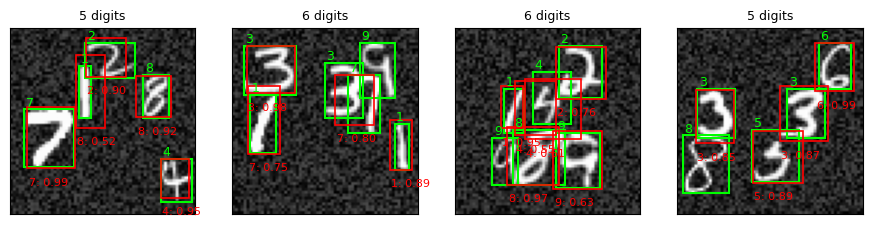

In [20]:
Xc, Bc, Lc = make_set(x_test, y_test, 500, n_min=4, n_max=6, max_iou=0.4, sizes=(20, 28))
n_obj_c = sum(len(b) for b in Bc)
lost_c = sum(len(encode(b, l)[1]) for b, l in zip(Bc, Lc))
raw_c = [decode(p, score_thr=0.05) for p in detector.predict(Xc, verbose=0)]
print(f"crowded test: {n_obj_c:,} digits in 500 scenes | centres sharing a cell: {lost_c} ({100 * lost_c / n_obj_c:.1f}%)")
CROWD = {}
for name, thr in [("NMS 0.45", 0.45), ("NMS 0.20", 0.2), ("NMS off", 1.0)]:
    dl_ = [nms(d, thr) for d in raw_c]
    p, rc, *_ = precision_recall(judge(dl_, Bc, Lc), n_obj_c)
    CROWD[name] = (p, rc, mean_ap(dl_, Bc, Lc)[0])
    print(f"{name:<9} precision {p:.3f} | recall {rc:.3f} | mAP@0.5 {CROWD[name][2]:.3f}")
print(f"uncrowded, for comparison: precision {P50:.3f} | recall {R50:.3f} | mAP@0.5 {MAP50:.3f}")
fig, ax = plt.subplots(1, 4, figsize=(11, 3))
for k, a in enumerate(ax):
    d = nms(raw_c[k]); show(a, Xc[k], Bc[k], Lc[k], dets=d[d[:, 4] >= 0.5], title=f"{len(Bc[k])} digits")
plt.show()

### Why we see this

Recall falls from 0.862 to 0.549 with the same weights. Now question the three suspects. **Shared cells**:
41 digits of 2,504, under 2%. Real, and incurable with one prediction per cell, but far too few to explain
the fall. **NMS**: turning it off wins back half a point of recall, and tightening it to 0.20 loses about a
point. Also small. **Digits covering each other**: this is the main cause. The detector was trained on
scenes where digits barely touch, and here strokes of one digit run through the box of another. It is being
tested on pictures unlike its training pictures, and no setting of the decoder can repair that.

The lesson is about diagnosis: the grid and NMS are the famous weaknesses in crowds, and at real densities
they do bite. But measure before you blame. Real detectors meet crowds with crowded training data, with
several predictions per location and with several grids of different coarseness, and still find crowds hard.

---
## Step 21 - The scale problem between the three losses

Step 12 multiplied the box part by 50. Is that number doing anything? Train two short runs (6 epochs on 5,000
scenes each, same seed) with `w_box = 1` and `w_box = 50`, and score both at the lenient and the strict
threshold.

**Predict before you run:** the box weight should matter most for which score: mAP at IoU 0.5, or at 0.75?

In [21]:
WEIGHT_RUNS = {}
for w in (1.0, 50.0):
    keras.utils.set_random_seed(SEED)
    m = build_detector()
    m.compile(optimizer=keras.optimizers.Adam(2e-3), loss=make_loss(w_box=w))
    m.fit(Xtr[:5000], Ttr[:5000], batch_size=BATCH, epochs=6, verbose=0)
    dl_ = [nms(decode(p, score_thr=0.05)) for p in m.predict(Xte, verbose=0)]
    WEIGHT_RUNS[w] = (mean_ap(dl_, Bte, Lte, 0.5)[0], mean_ap(dl_, Bte, Lte, 0.75)[0])
    print(f"w_box = {w:>4}: mAP@0.5 {WEIGHT_RUNS[w][0]:.3f} | mAP@0.75 {WEIGHT_RUNS[w][1]:.3f}   (short run: 6 epochs, 5,000 scenes)")

print(f"\nwhole lab: {time.time() - t_start:.0f}s")
print("summary (the main detector, 1,000 uncrowded test scenes; a miniature, not a benchmark):")
print(f"  parameters {detector.count_params():,} | precision {P50:.3f} | recall {R50:.3f} at score 0.5, IoU 0.5")
print(f"  mAP@0.5 {MAP50:.3f} | mAP@0.75 {MAP75:.3f} | mAP@[0.5:0.95] {MAP_COCO:.3f}")

w_box =  1.0: mAP@0.5 0.551 | mAP@0.75 0.045   (short run: 6 epochs, 5,000 scenes)


w_box = 50.0: mAP@0.5 0.697 | mAP@0.75 0.389   (short run: 6 epochs, 5,000 scenes)

whole lab: 236s
summary (the main detector, 1,000 uncrowded test scenes; a miniature, not a benchmark):
  parameters 98,127 | precision 0.941 | recall 0.862 at score 0.5, IoU 0.5
  mAP@0.5 0.905 | mAP@0.75 0.711 | mAP@[0.5:0.95] 0.601


### Why we see this

The box numbers live between 0 and 1, so a box that is wrong by three pixels in width has a squared error of
about 0.002. Next to cross-entropy terms of size 0.1 to 1, that is invisible, and a network trained on the
plain sum learns to find and name digits while leaving its boxes loose. Multiplying the box part by 50 puts
the three parts on a comparable footing. The weight is not a law of nature: it is a statement about which
mistakes you mind, and it must be retuned whenever the units of any part change.

Measured here: with the plain sum, mAP at IoU 0.75 is 0.045; with the weight of 50 it is 0.389. At the lenient
0.5 the gap is smaller (0.551 against 0.697), because a loose box still passes. These are short runs, so both
are well below the main model's scores. The comparison between the two is the point, not the level.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Steps 9 and 11: `GRID = 4` (cells of 16 pixels), with a fourth `MaxPooling2D` after `conv4` so the map is 4 x 4 | How many digits are lost to shared cells now? What happens to recall? | |
| 2 | Step 12: `W_NOOBJ = 1.0`, then `0.1` | Which way do precision and recall move at score 0.5? | |
| 3 | Step 8: pass `sizes=(10, 16)` to `make_set` for the train and test sets | Recall on digits about 8 pixels tall after three poolings? | |
| 4 | Step 13: `EPOCHS = 4` | Which falls further behind, mAP at 0.5 or at 0.75? | |
| 5 | Step 8: `N_TRAIN = 2_000` | Which kind of error in Step 18 grows most? | |
| 6 | Step 15: make NMS class-aware (only suppress boxes of the same class) | More or fewer false positives? Which kind? | |
| 7 | Step 11: delete `conv4` and `conv5` (and their entries in `counts`; the two asserts will then ask you for the new parameter count and receptive field) | Predict both numbers. Which digits suffer: small or large? | |
| 8 | Step 8: train on scenes whose digits all lie in the left half; test on the usual scenes | Does a fully convolutional detector care where it saw its examples? | |

---
## Exercises

1. **Flip the scene.** Write `flip_lr(img, boxes)` that mirrors a scene left to right and moves the boxes with
   it (`x1' = 64 - x2`, `x2' = 64 - x1`). Test it with `decode(encode(...))`. Then flip only the image and
   train on the result: how fast does mAP fall? (Digits are not mirror-symmetric, so decide first whether this
   augmentation is even valid for the class labels.)
2. **Two predictions per cell.** Give every cell two boxes (30 outputs), one meant for tall narrow digits and
   one for wide ones, and assign each digit to the slot whose template shape it matches better. These are
   anchors. Does the number of digits lost to shared cells fall on the crowded scenes of Step 20?
3. **An IoU loss.** Replace the squared error on the box numbers with `1 - IoU` between the decoded predicted
   box and the true box, written in TensorFlow. Compare mAP at 0.75.
4. **Focal loss.** Replace the `w_noobj` trick by the focal loss of Chapter 6 on the objectness logit, with
   gamma 2. Does it change which cells fire near borders?
5. **Soft-NMS.** Instead of deleting an overlapping box, multiply its score by `1 - IoU` and keep it if the
   score stays above 0.05. Re-run Step 20.
6. **Eleven numbers or one?** Report recall at precision 0.95 instead of mAP. Which of the two would you put
   in front of a customer, and why?

---
## Cheat sheet

| Thing | In one line |
|---|---|
| Corners / centre-size | `(x1, y1, x2, y2)` / `(cx, cy, w, h)`; convert before every IoU |
| IoU | overlap area / (area A + area B - overlap area) |
| Grid target | `(8, 8, 15)`: objectness, `tx, ty, tw, th`, ten classes |
| Target assignment | the cell that holds the box centre owns the object; all other cells are background |
| First test | `decode(encode(truth)) == truth` |
| Loss | objectness at every cell + box and class only at cells that own an object, each with a weight |
| Score of a detection | objectness x best class probability |
| NMS | sort by score, keep the best, drop boxes overlapping it by more than a threshold, repeat |
| True positive | right class, IoU at least the threshold with a not-yet-matched true box |
| Precision / recall | TP / detections made, TP / true objects |
| AP | area under the precision-recall curve of one class; mAP averages the classes |

| Rule of thumb | Why |
|---|---|
| Always state the IoU threshold with a score | the same detector scored very differently at 0.5 and at 0.75 here |
| Choose score and NMS thresholds on validation data | they are settings of the product, not of the model |
| Look at the kinds of error, not only at mAP | loose boxes, wrong classes and duplicates need different cures |
| Weight the three losses on purpose | their raw sizes differ by orders of magnitude |
| When you move the image, move the boxes | a flipped image with unflipped boxes trains without any error message |

**What changes at full size.** A real detector starts from a backbone pretrained on millions of images,
predicts at several scales through a feature pyramid so that small and large objects each get a suitable grid,
makes thousands of predictions per image instead of 64, uses anchors or a point-based rule (or, in DETR, a
one-to-one matching) to assign targets, and trains for hours to days on labelled photographs. In practice you
do not write any of this: you load a pretrained detector and fine-tune it on your boxes. Having written each
part once, you know what its settings mean.